In [ ]:
from pathlib import Path

# Repo root, found by walking up until the data/ folder: works whatever the notebook's working directory is.
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "data").is_dir())

## qualidade dos dados

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd # Adicionado apenas por garantia, pois você usa no código

def nulls_e_zeros(df, title):
    # 1. Identifica os anos únicos disponíveis no dataframe e os ordena
    anos = sorted(df['Período'].dropna().unique())
    num_anos = len(anos)

    # Identifica apenas as colunas de variáveis (excluindo 'Período' e 'Distrito')
    cols_variaveis = [col for col in df.columns if col not in ['Período', 'Distrito']]

    # 2. Cria a figura com subplots (1 linha, múltiplas colunas)
    fig, axes = plt.subplots(nrows=1, ncols=num_anos, figsize=(5 * num_anos, 35), sharey=True)

    # Garante que axes seja iterável caso haja apenas 1 ano na base
    if num_anos == 1:
        axes = [axes]

    # 3. Loop para calcular proporções e plotar cada ano em seu respectivo eixo (ax)
    for ax, ano in zip(axes, anos):
        # Filtra os dados especificamente para o ano do loop
        df_ano = df[df['Período'] == ano]
        
        dados_proporcao = []

        for col in cols_variaveis:
            # Converte os dados para numérico
            s = pd.to_numeric(df_ano[col], errors='coerce')
            total = len(s)

            # Trata caso não haja registros para o ano (evita erro de divisão por zero)
            if total == 0:
                perc_nulos, perc_zeros, perc_maiores_zero = 100, 0, 0
            else:
                perc_nulos = (s.isna().sum() / total) * 100
                perc_zeros = ((s == 0).sum() / total) * 100
                perc_maiores_zero = ((s > 0).sum() / total) * 100

            dados_proporcao.append({
                'Variável': col,
                'Nulos (%)': perc_nulos,
                'Zeros (%)': perc_zeros,
                'Valores > 0 (%)': perc_maiores_zero
            })

        df_prop = pd.DataFrame(dados_proporcao).set_index('Variável')

        # Plotagem das barras no subplot atual (ax)
        df_prop[['Nulos (%)', 'Zeros (%)', 'Valores > 0 (%)']].plot(
            kind='barh',
            stacked=True,
            ax=ax,
            color=['#e74c3c', '#f1c40f', '#2ecc71'],  
            width=0.8,
            legend=False 
        )

        # Ajustes estéticos individuais de cada subplot
        ax.set_title(f'Ano: {int(ano)}', fontsize=25, pad=5)
        ax.set_xlabel('Porcentagem (%)', fontsize=20) # <-- Aumentado o texto do eixo X também para manter proporção
        ax.tick_params(axis='x', labelsize=15)        # <-- Aumentado os números do eixo X
        ax.set_xlim(0, 100)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
        
        # Mantém o rótulo do eixo Y apenas no primeiro gráfico
        if ax == axes[0]:
            ax.set_ylabel('Variáveis', fontsize=25)
            # AUMENTANDO O TAMANHO DOS RÓTULOS (nomes das variáveis) DO EIXO Y
            ax.tick_params(axis='y', labelsize=20)    # <-- LINHA ADICIONADA/MODIFICADA
        else:
            ax.set_ylabel('')
            # Oculta os ticks y nos outros gráficos para ficar mais limpo
            ax.tick_params(axis='y', which='both', length=0) 

    # Inverte o eixo Y apenas do primeiro eixo (afeta todos devido ao sharey=True)
    axes[0].invert_yaxis()

    # Adiciona um título geral para a imagem completa
    fig.suptitle('Proporção de Valores Nulos, Zerados e >0 por Variável ao longo dos Anos', fontsize=35, y=1.01)

    # Pega os handles do último gráfico para criar uma legenda única do lado direito
    handles, labels = axes[-1].get_legend_handles_labels()
    
    # AUMENTANDO A FONTE DA LEGENDA E DO TÍTULO DA LEGENDA
    fig.legend(
        handles, 
        labels, 
        title='Categoria', 
        bbox_to_anchor=(1.01, 0.98), 
        loc='upper left', 
        fontsize=25,           # <-- Tamanho da fonte dos itens da legenda
        title_fontsize=30      # <-- Tamanho da fonte do título da legenda ("Categoria")
    )

    plt.tight_layout()

    # 1. Salva a imagem em alta resolução
    plt.savefig(
        ROOT / f'analysis/figures/nullsezeros_{title}.png', 
        dpi=300,                              
        bbox_inches='tight',                
        pad_inches=0.2,                     
        facecolor='white',                  
        transparent=False
    )

    plt.show()

In [42]:
import pandas as pd
df1sel = pd.read_csv(ROOT / "data/interim/merged_1sel_full.csv", delimiter=';')
df1sel = df1sel[(df1sel['Período']>=2016) & (df1sel['Período'] < 2026)]
df1sel = df1sel.drop(columns=['Unnamed: 0'])

df3sel = pd.read_csv(ROOT / "data/processed/sel3_full.csv", delimiter=';')
df3sel = df3sel[(df3sel['Período']>=2016) & (df3sel['Período'] < 2026)]
df3sel = df3sel.drop(columns=['Unnamed: 0'])

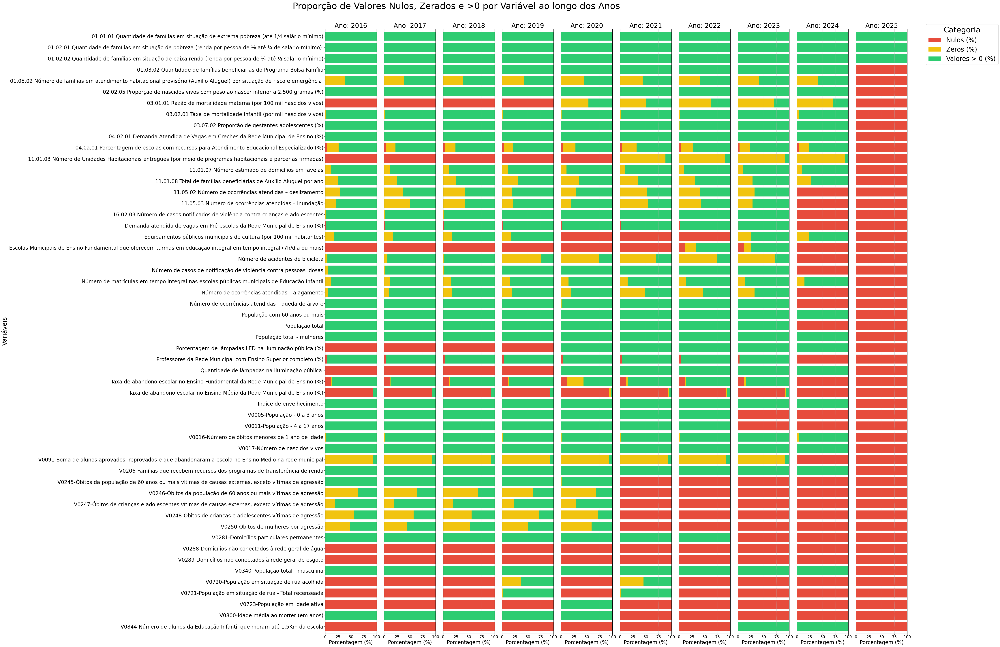

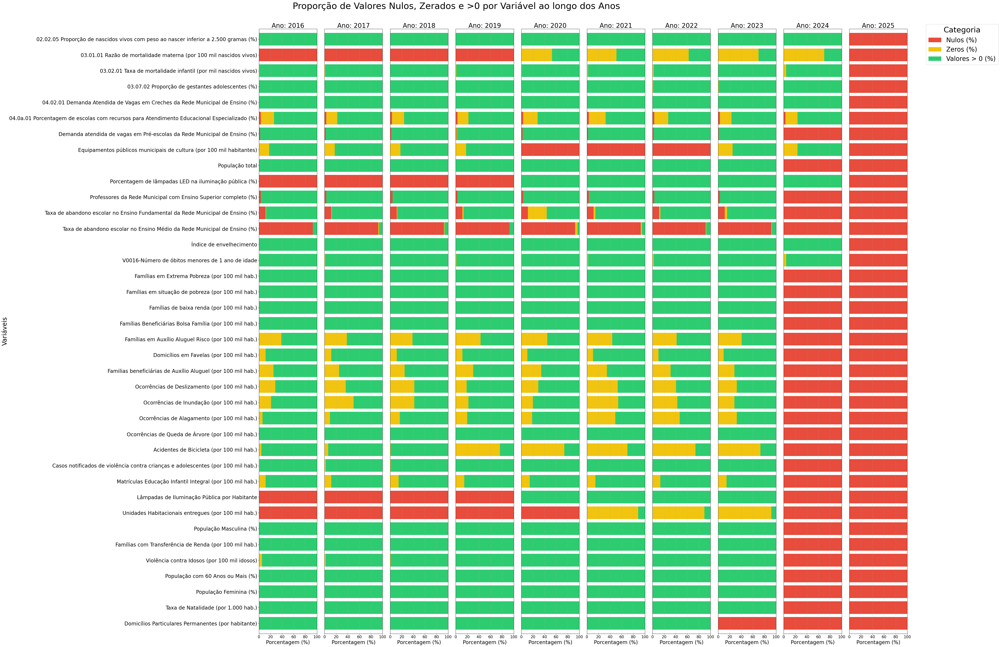

In [43]:
nulls_e_zeros(df1sel, 'df1sel')
nulls_e_zeros(df3sel, 'df3sel')

## correlação

In [33]:
df3sel = pd.read_csv(ROOT / "data/processed/sel3_full.csv", delimiter=';')
df3sel = df3sel[(df3sel['Período']>=2016) & (df3sel['Período'] < 2026)]
df3sel = df3sel.drop(columns=['Unnamed: 0'])

                                                    02.02.05 Proporção de nascidos vivos com peso ao nascer inferior a 2.500 gramas (%)  \
02.02.05 Proporção de nascidos vivos com peso a...                                           1.000000                                     
03.01.01 Razão de mortalidade materna (por 100 ...                                           0.095659                                     
03.02.01 Taxa de mortalidade infantil (por mil ...                                           0.171554                                     
03.07.02 Proporção de gestantes adolescentes (%)                                             0.104452                                     
04.02.01 Demanda Atendida de Vagas em Creches d...                                           0.110667                                     
04.0a.01 Porcentagem de escolas com recursos pa...                                           0.021740                                     
Demanda atendida de vagas e

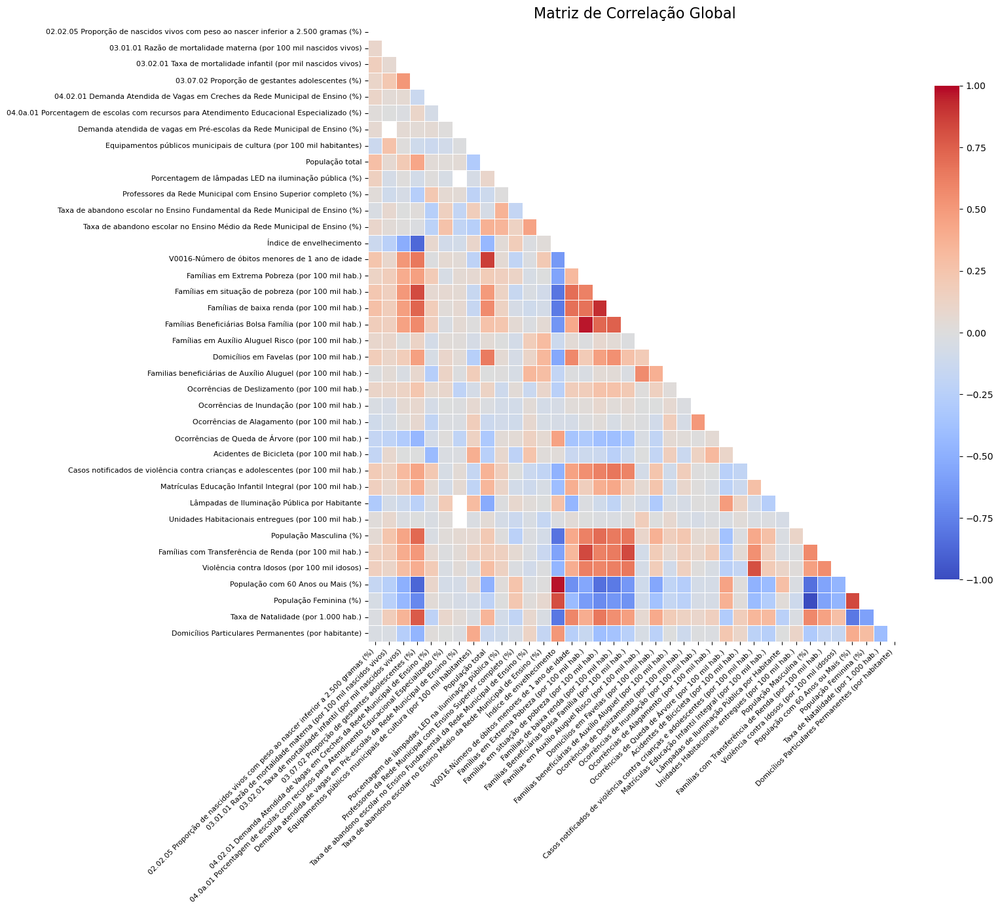

Total de pares com |correlação| >= 0.5: 83 de 703 pares possíveis


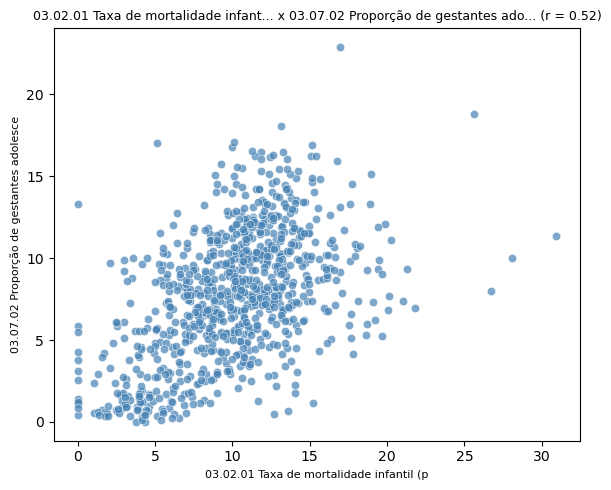

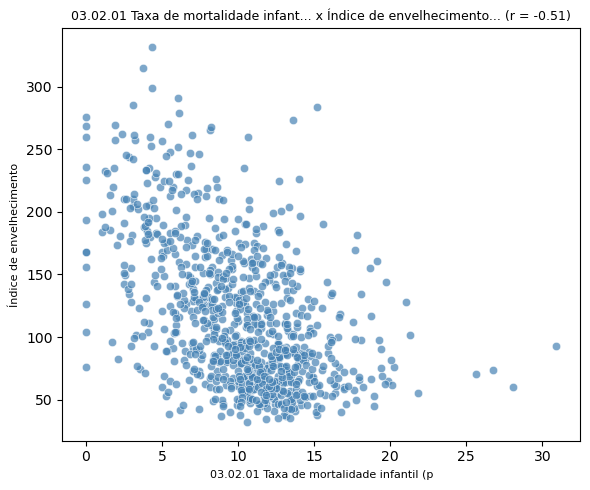

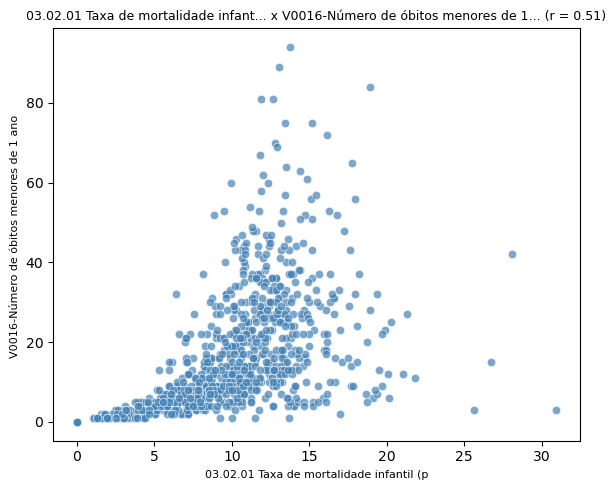

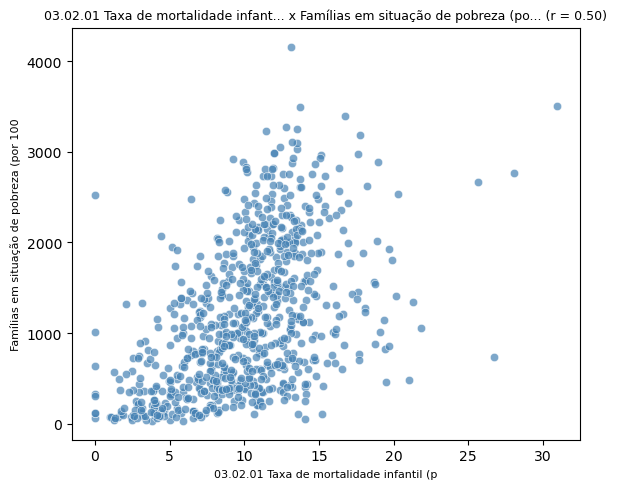

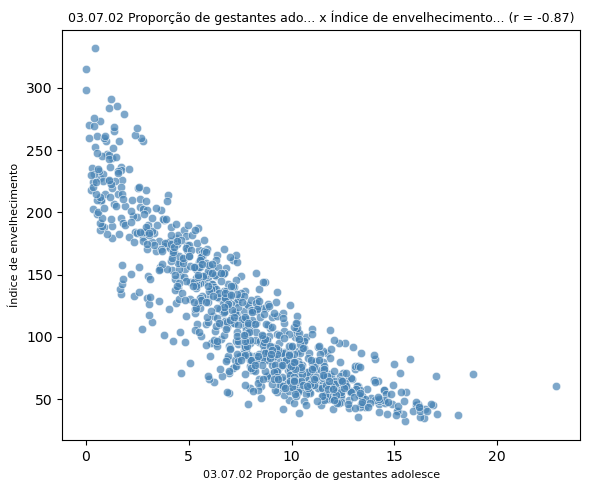

...

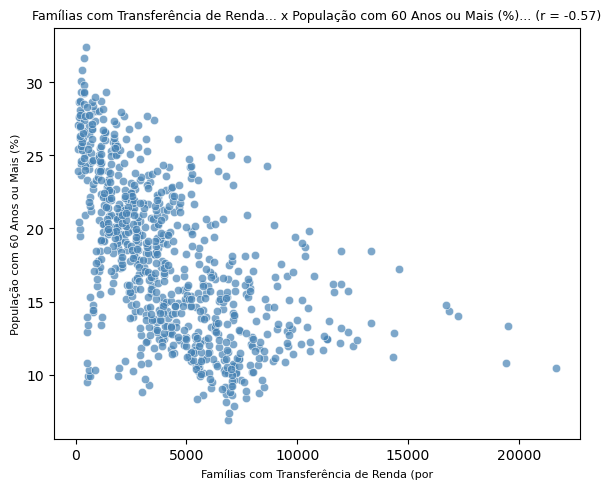

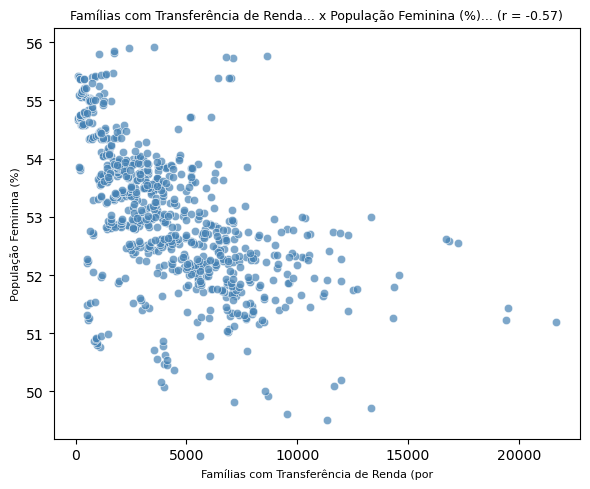

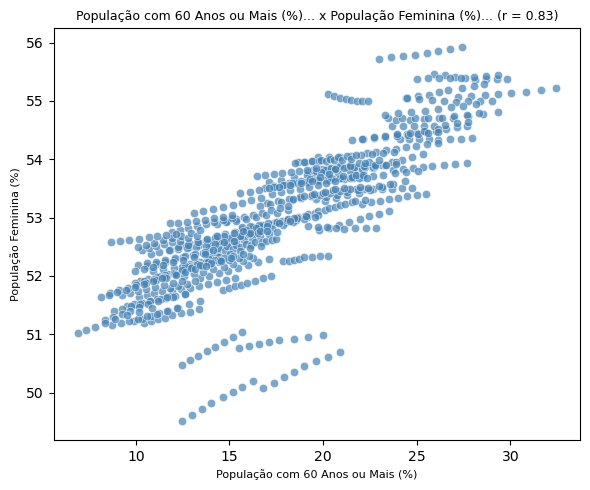

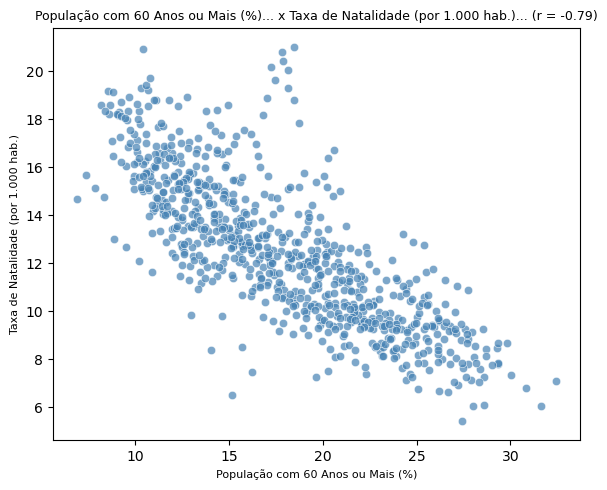

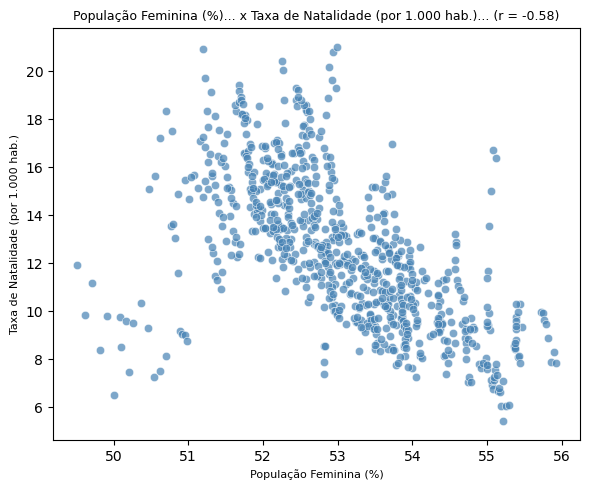

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

def plotar_correlacao(df, colunas, title):
    """
    Plota um Heatmap de correlação para as colunas selecionadas.
    O método .corr() do pandas já ignora pares de valores nulos automaticamente
    (correlação calculada pairwise).
    """
    matriz_corr = df[colunas].corr()

    # Máscara para esconder a parte superior repetida do triângulo
    mask = np.triu(np.ones_like(matriz_corr, dtype=bool))

    plt.figure(figsize=(16, 14))
    sns.heatmap(matriz_corr,
                mask=mask,
                annot=False,
                cmap='coolwarm',
                center=0,
                vmin=-1, vmax=1,
                linewidths=0.5,
                cbar_kws={"shrink": .8})

    plt.title('Matriz de Correlação Global', fontsize=16)
    
    # Rotação em 45 graus e alinhamento à direita para facilitar a leitura
    plt.xticks(fontsize=8, rotation=45, ha='right')
    plt.yticks(fontsize=8)
    plt.tight_layout()

    plt.savefig(
        ROOT / f'analysis/figures/correlacao{title}.png', 
        dpi=300,                              
        bbox_inches='tight',                
        pad_inches=0.2,                     
        facecolor='white',                  
        transparent=False
    )
    plt.show()

    return matriz_corr


def plotar_dispersao(df, colunas, matriz_corr=None, limiar_corr=0.5):
    """
    Plota um scatter-plot apenas para pares de variáveis cuja correlação
    absoluta seja maior ou igual a `limiar_corr`. Remove os nulos de cada
    par antes de plotar (dropna aplicado apenas às duas colunas envolvidas
    em cada par).
    """
    if matriz_corr is None:
        matriz_corr = df[colunas].corr()

    n = len(colunas)

    pares_relevantes = []
    for i in range(n):
        for j in range(i + 1, n):
            col_x, col_y = colunas[i], colunas[j]
            r = matriz_corr.loc[col_x, col_y]
            if pd.notna(r) and abs(r) >= limiar_corr:
                pares_relevantes.append((col_x, col_y, r))

    print(f"Total de pares com |correlação| >= {limiar_corr}: {len(pares_relevantes)} de {n * (n - 1) // 2} pares possíveis")
    print('=' * 80)

    for col_x, col_y, r in pares_relevantes:
        dados_par = df[[col_x, col_y]].dropna()

        if dados_par.empty:
            continue

        plt.figure(figsize=(6, 5))
        sns.scatterplot(data=dados_par, x=col_x, y=col_y, color='steelblue', alpha=0.7)
        plt.title(f'{col_x[:35]}... x {col_y[:35]}... (r = {r:.2f})', fontsize=9)
        plt.xlabel(col_x[:40], fontsize=8)
        plt.ylabel(col_y[:40], fontsize=8)
        plt.tight_layout()
        plt.show()



colunas_numericas = df3sel.drop(columns=['Período', 'Distrito']).columns
# Plotar correlação de todas as variáveis numéricas
matriz_corr = plotar_correlacao(df3sel, colunas_numericas, 'sel3')

# Plotar dispersão apenas dos pares com correlação relevante (|r| >= 0.5)
plotar_dispersao(df3sel, colunas_numericas, matriz_corr=matriz_corr, limiar_corr=0.5)

## Analise Univariada

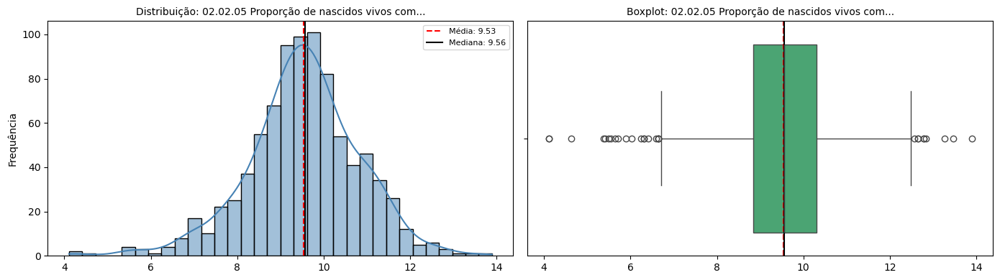

Variável: 02.02.05 Proporção de nascidos vivos com peso ao nascer inferior a 2.500 gramas (%)
--------------------------------------------------------------------------------
Média                          9.53
Mediana                        9.56
Variância                      1.67
Desvio Padrão                  1.29
Nº válidos                      864
Nº nulos removidos               96



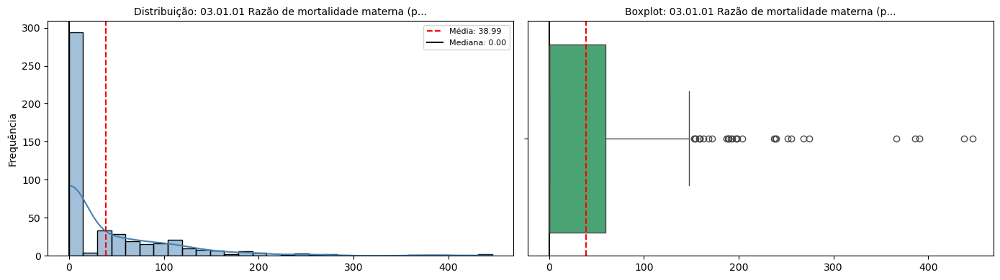

Variável: 03.01.01 Razão de mortalidade materna (por 100 mil nascidos vivos)
--------------------------------------------------------------------------------
Média                         38.99
Mediana                        0.00
Variância                   4559.44
Desvio Padrão                 67.52
Nº válidos                      480
Nº nulos removidos              480



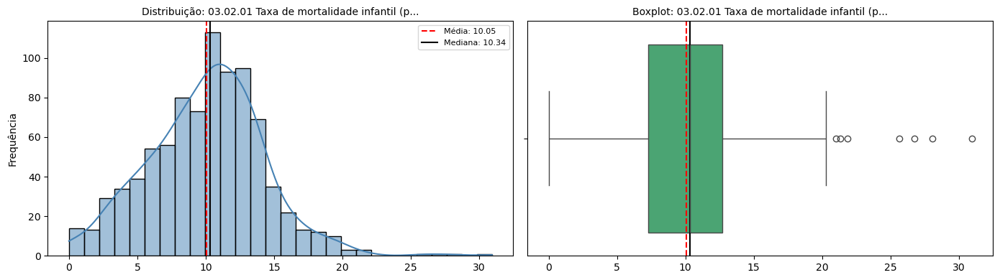

Variável: 03.02.01 Taxa de mortalidade infantil (por mil nascidos vivos)
--------------------------------------------------------------------------------
Média                         10.05
Mediana                       10.34
Variância                     17.87
Desvio Padrão                  4.23
Nº válidos                      864
Nº nulos removidos               96



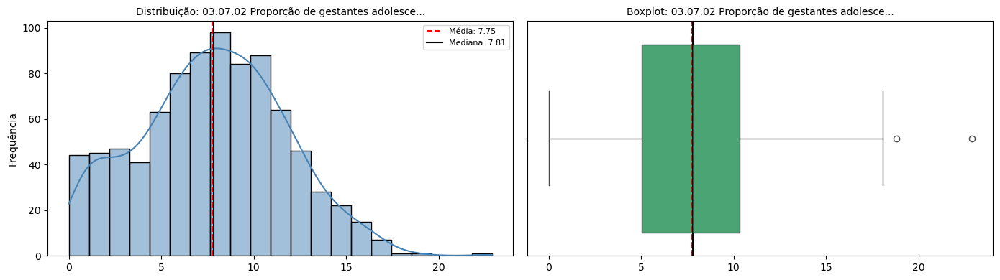

Variável: 03.07.02 Proporção de gestantes adolescentes (%)
--------------------------------------------------------------------------------
Média                          7.75
Mediana                        7.81
Variância                     15.41
Desvio Padrão                  3.93
Nº válidos                      864
Nº nulos removidos               96



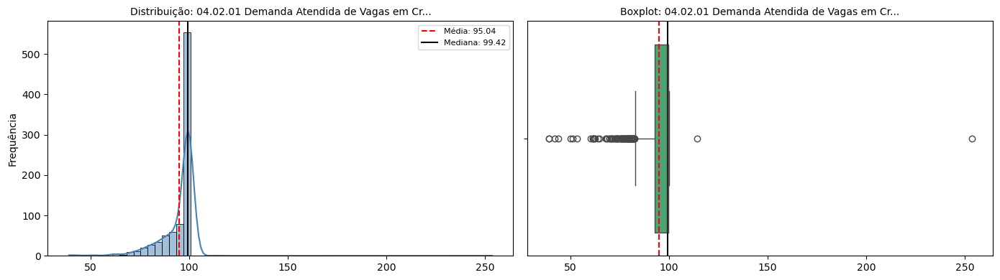

Variável: 04.02.01 Demanda Atendida de Vagas em Creches da Rede Municipal de Ensino (%)
--------------------------------------------------------------------------------
Média                         95.04
Mediana                       99.42
Variância                    108.14
Desvio Padrão                 10.40
Nº válidos                      864
Nº nulos removidos               96



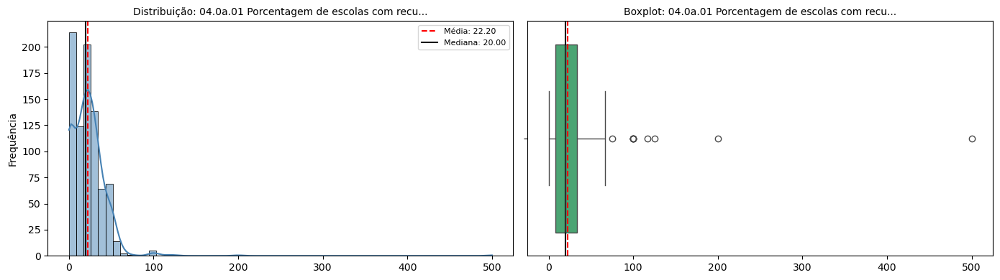

Variável: 04.0a.01 Porcentagem de escolas com recursos para Atendimento Educacional Especializado (%)
--------------------------------------------------------------------------------
Média                         22.20
Mediana                       20.00
Variância                    626.16
Desvio Padrão                 25.02
Nº válidos                      837
Nº nulos removidos              123



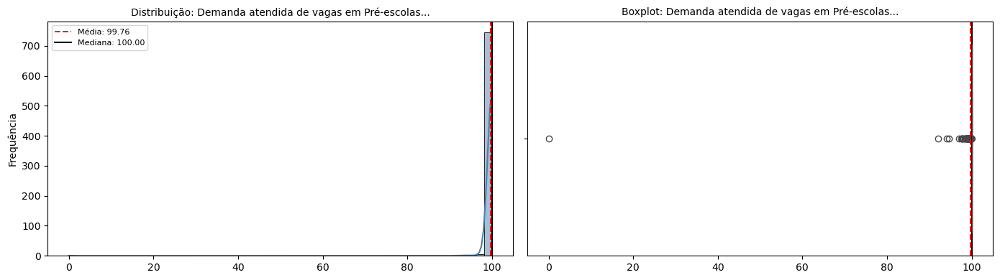

Variável: Demanda atendida de vagas em Pré-escolas da Rede Municipal de Ensino (%)
--------------------------------------------------------------------------------
Média                         99.76
Mediana                      100.00
Variância                     13.48
Desvio Padrão                  3.67
Nº válidos                      754
Nº nulos removidos              206



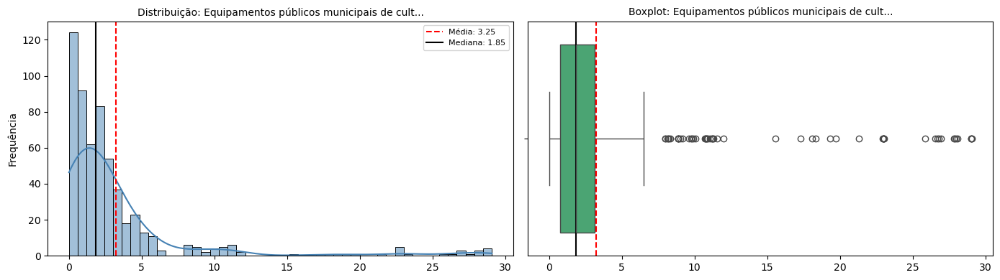

Variável: Equipamentos públicos municipais de cultura (por 100 mil habitantes)
--------------------------------------------------------------------------------
Média                          3.25
Mediana                        1.85
Variância                     26.94
Desvio Padrão                  5.19
Nº válidos                      576
Nº nulos removidos              384



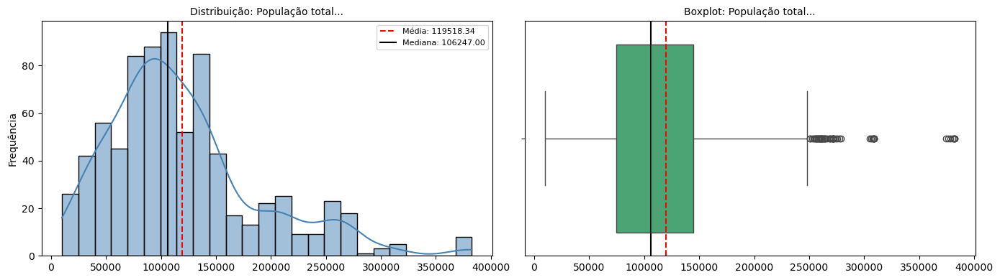

Variável: População total
--------------------------------------------------------------------------------
Média                     119518.34
Mediana                   106247.00
Variância             4795662475.89
Desvio Padrão              69250.72
Nº válidos                      768
Nº nulos removidos              192



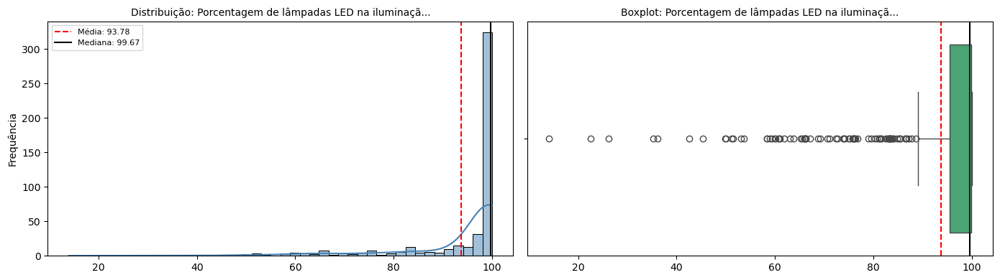

Variável: Porcentagem de lâmpadas LED na iluminação pública (%)
--------------------------------------------------------------------------------
Média                         93.78
Mediana                       99.67
Variância                    169.97
Desvio Padrão                 13.04
Nº válidos                      480
Nº nulos removidos              480



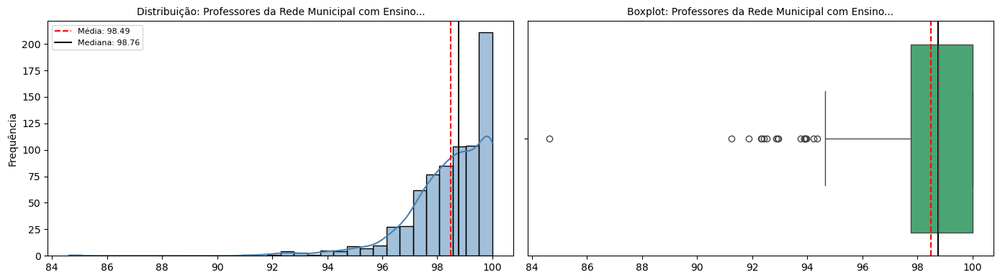

Variável: Professores da Rede Municipal com Ensino Superior completo (%)
--------------------------------------------------------------------------------
Média                         98.49
Mediana                       98.76
Variância                      2.44
Desvio Padrão                  1.56
Nº válidos                      743
Nº nulos removidos              217



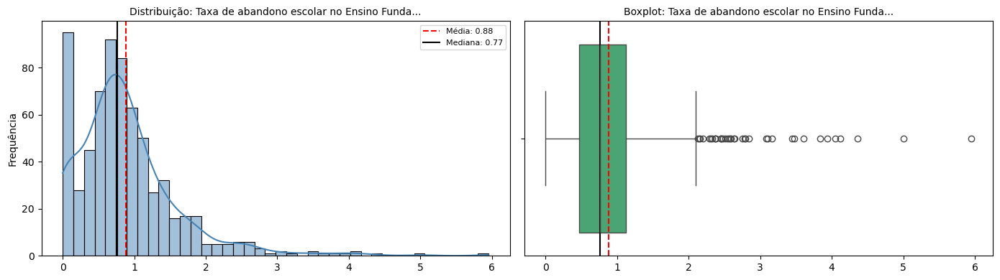

Variável: Taxa de abandono escolar no Ensino Fundamental da Rede Municipal de Ensino (%)
--------------------------------------------------------------------------------
Média                          0.88
Mediana                        0.77
Variância                      0.53
Desvio Padrão                  0.73
Nº válidos                      680
Nº nulos removidos              280



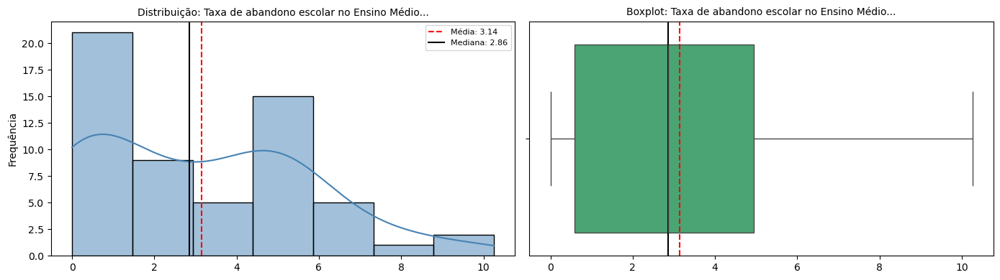

Variável: Taxa de abandono escolar no Ensino Médio da Rede Municipal de Ensino (%)
--------------------------------------------------------------------------------
Média                          3.14
Mediana                        2.86
Variância                      7.07
Desvio Padrão                  2.66
Nº válidos                       58
Nº nulos removidos              902



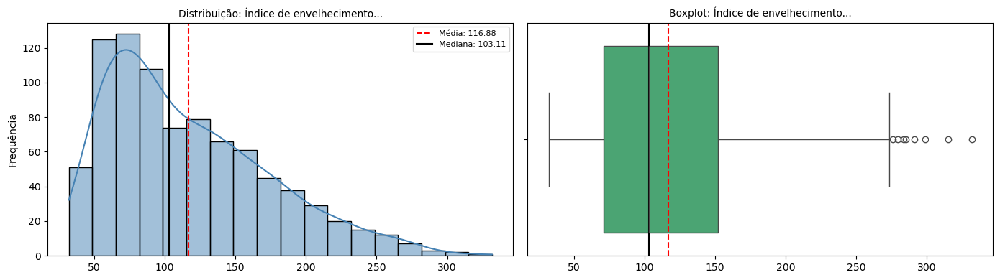

Variável: Índice de envelhecimento
--------------------------------------------------------------------------------
Média                        116.88
Mediana                      103.11
Variância                   3286.08
Desvio Padrão                 57.32
Nº válidos                      864
Nº nulos removidos               96



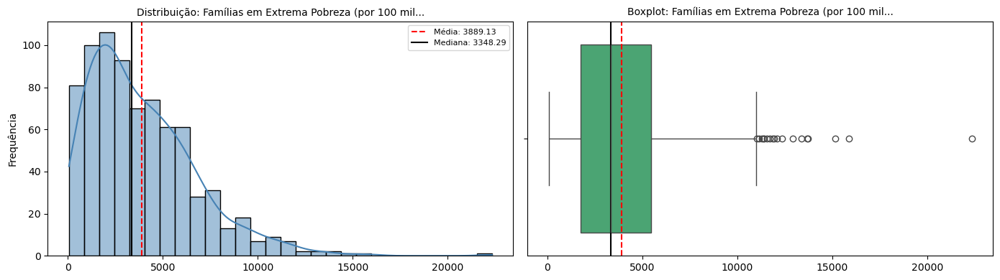

Variável: Famílias em Extrema Pobreza (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       3889.13
Mediana                     3348.29
Variância                8045062.76
Desvio Padrão               2836.38
Nº válidos                      768
Nº nulos removidos              192



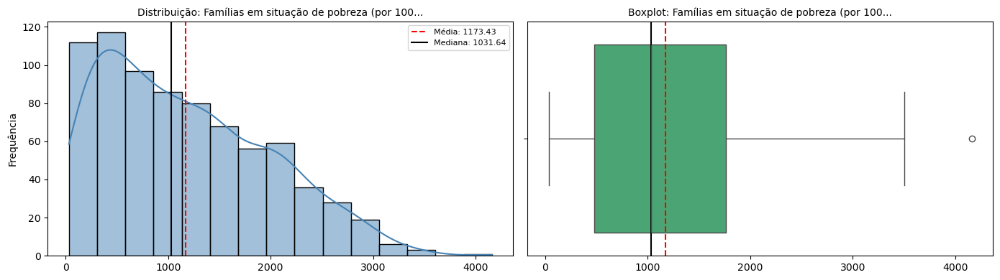

Variável: Famílias em situação de pobreza (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       1173.43
Mediana                     1031.64
Variância                 661061.00
Desvio Padrão                813.06
Nº válidos                      768
Nº nulos removidos              192



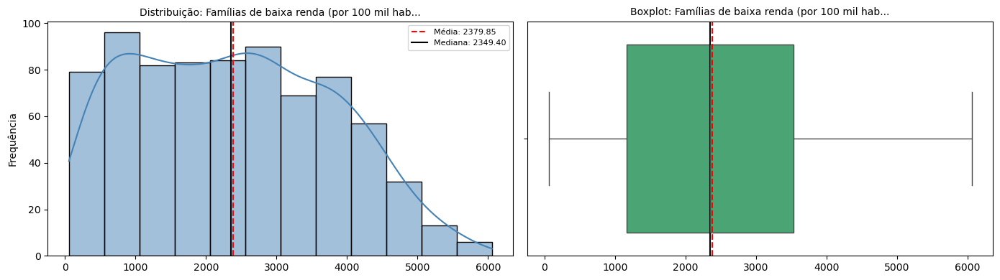

Variável: Famílias de baixa renda (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       2379.85
Mediana                     2349.40
Variância                1955550.55
Desvio Padrão               1398.41
Nº válidos                      768
Nº nulos removidos              192



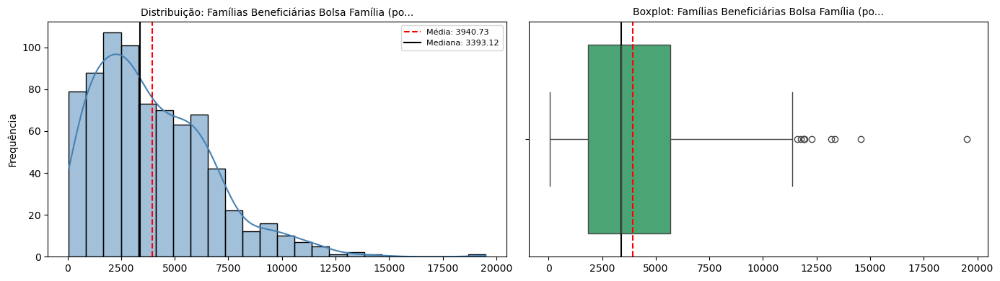

Variável: Famílias Beneficiárias Bolsa Família (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       3940.73
Mediana                     3393.12
Variância                7479241.73
Desvio Padrão               2734.82
Nº válidos                      768
Nº nulos removidos              192



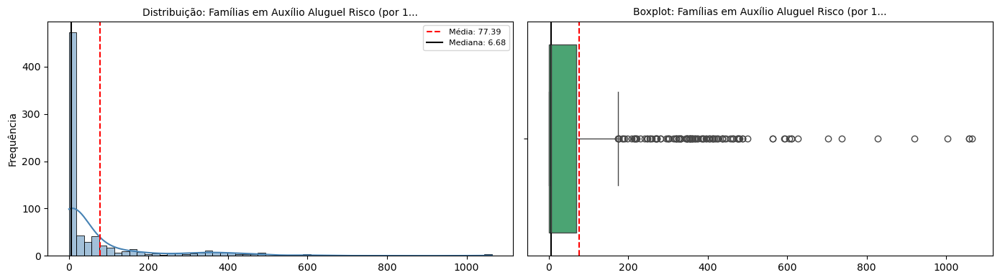

Variável: Famílias em Auxílio Aluguel Risco (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                         77.39
Mediana                        6.68
Variância                  23900.28
Desvio Padrão                154.60
Nº válidos                      768
Nº nulos removidos              192



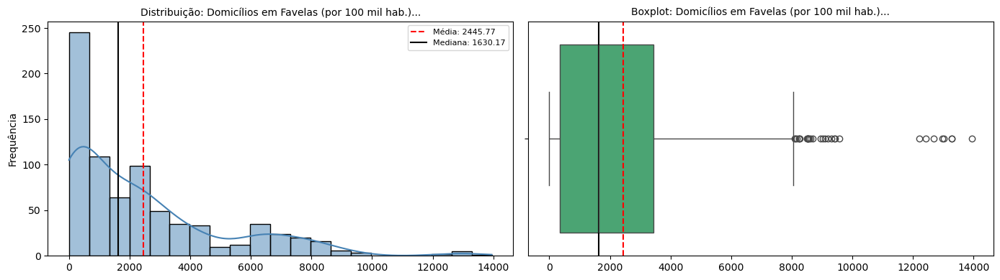

Variável: Domicílios em Favelas (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       2445.77
Mediana                     1630.17
Variância                6991428.19
Desvio Padrão               2644.13
Nº válidos                      768
Nº nulos removidos              192



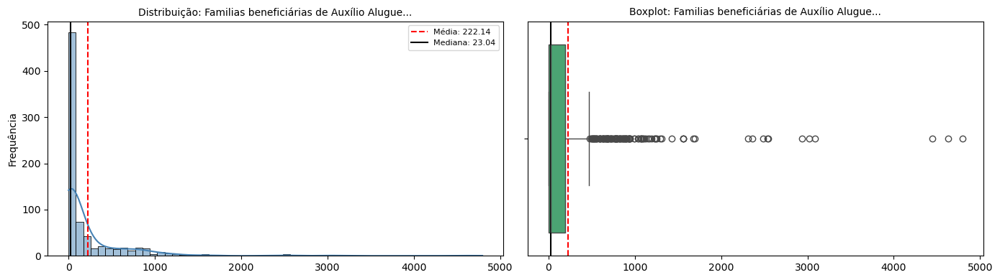

Variável: Familias beneficiárias de Auxílio Aluguel (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                        222.14
Mediana                       23.04
Variância                 235510.07
Desvio Padrão                485.29
Nº válidos                      768
Nº nulos removidos              192



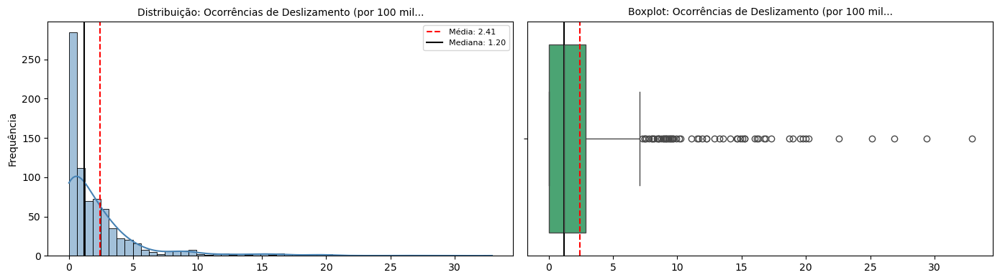

Variável: Ocorrências de Deslizamento (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                          2.41
Mediana                        1.20
Variância                     15.38
Desvio Padrão                  3.92
Nº válidos                      768
Nº nulos removidos              192



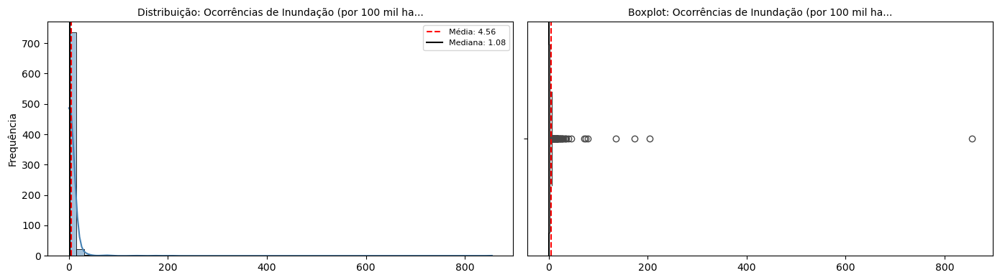

Variável: Ocorrências de Inundação (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                          4.56
Mediana                        1.08
Variância                   1102.00
Desvio Padrão                 33.20
Nº válidos                      768
Nº nulos removidos              192



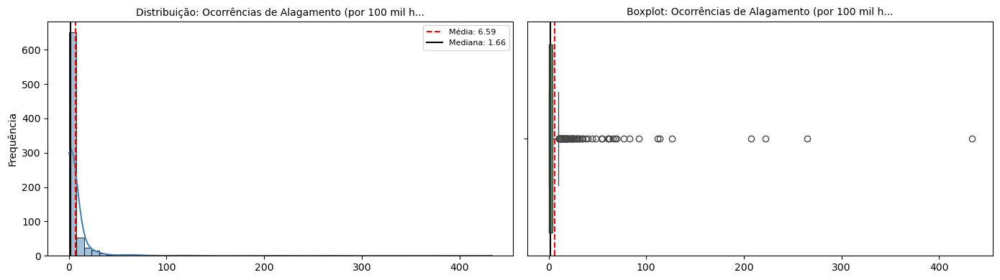

Variável: Ocorrências de Alagamento (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                          6.59
Mediana                        1.66
Variância                    589.22
Desvio Padrão                 24.27
Nº válidos                      768
Nº nulos removidos              192



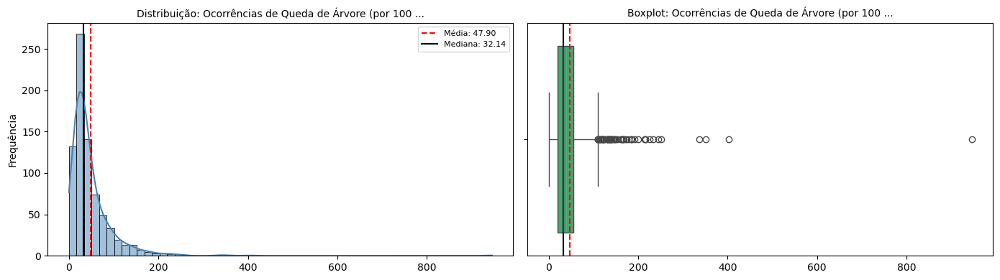

Variável: Ocorrências de Queda de Árvore (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                         47.90
Mediana                       32.14
Variância                   2991.20
Desvio Padrão                 54.69
Nº válidos                      768
Nº nulos removidos              192



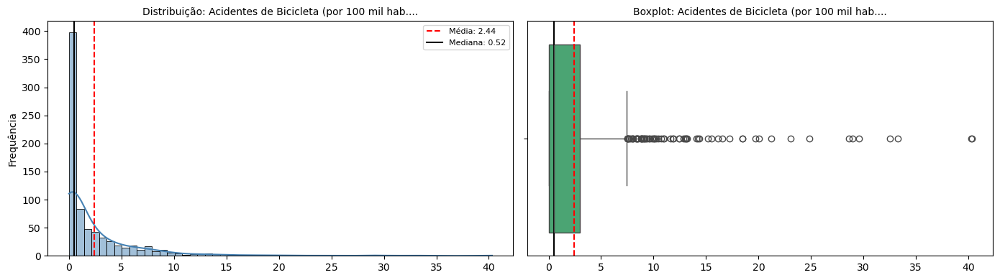

Variável: Acidentes de Bicicleta (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                          2.44
Mediana                        0.52
Variância                     21.72
Desvio Padrão                  4.66
Nº válidos                      768
Nº nulos removidos              192



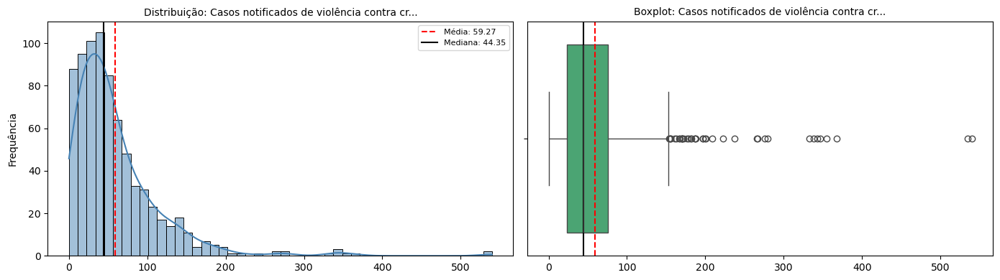

Variável: Casos notificados de violência contra crianças e adolescentes (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                         59.27
Mediana                       44.35
Variância                   3311.72
Desvio Padrão                 57.55
Nº válidos                      768
Nº nulos removidos              192



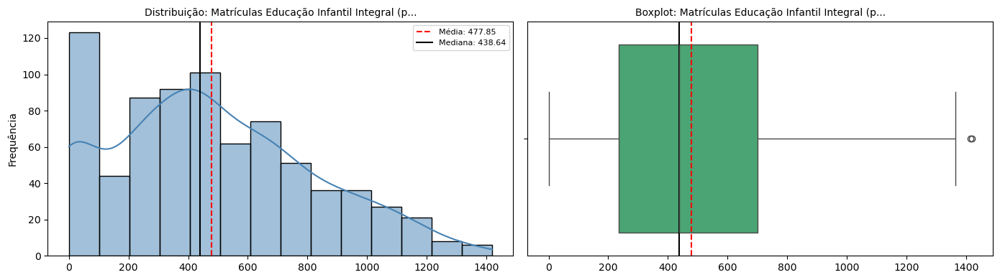

Variável: Matrículas Educação Infantil Integral (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                        477.85
Mediana                      438.64
Variância                 113731.91
Desvio Padrão                337.24
Nº válidos                      768
Nº nulos removidos              192



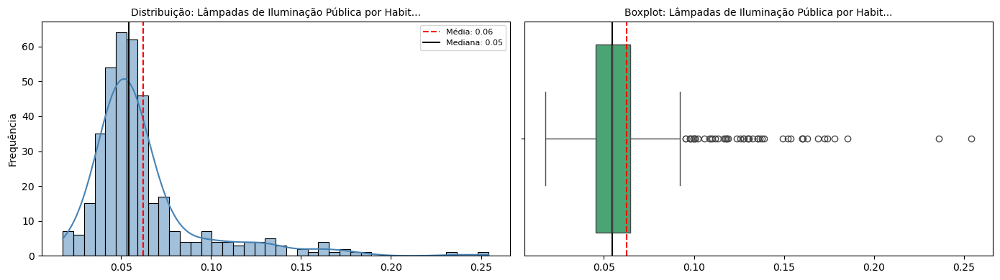

Variável: Lâmpadas de Iluminação Pública por Habitante
--------------------------------------------------------------------------------
Média                          0.06
Mediana                        0.05
Variância                      0.00
Desvio Padrão                  0.03
Nº válidos                      384
Nº nulos removidos              576



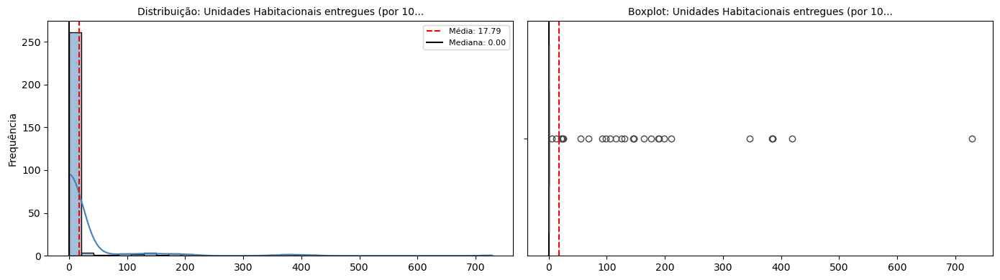

Variável: Unidades Habitacionais entregues (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                         17.79
Mediana                        0.00
Variância                   5380.82
Desvio Padrão                 73.35
Nº válidos                      288
Nº nulos removidos              672



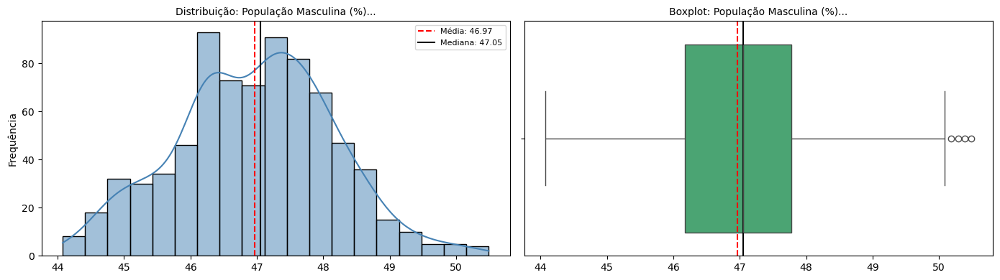

Variável: População Masculina (%)
--------------------------------------------------------------------------------
Média                         46.97
Mediana                       47.05
Variância                      1.41
Desvio Padrão                  1.19
Nº válidos                      768
Nº nulos removidos              192



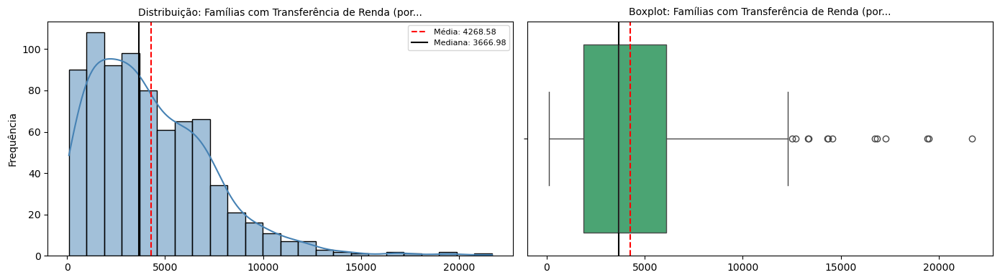

Variável: Famílias com Transferência de Renda (por 100 mil hab.)
--------------------------------------------------------------------------------
Média                       4268.58
Mediana                     3666.98
Variância                9849397.15
Desvio Padrão               3138.37
Nº válidos                      768
Nº nulos removidos              192



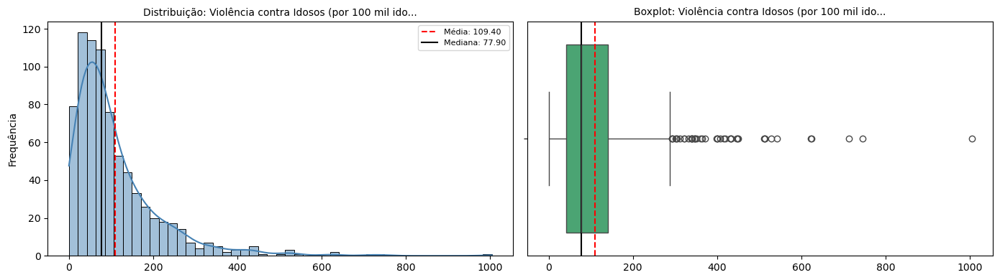

Variável: Violência contra Idosos (por 100 mil idosos)
--------------------------------------------------------------------------------
Média                        109.40
Mediana                       77.90
Variância                  11264.33
Desvio Padrão                106.13
Nº válidos                      768
Nº nulos removidos              192



KeyError: 'Taxa de Mortalidade Infantil (por 1.000 nascidos vivos)'

In [46]:
def plotar_univariada_numerica(df, colunas):
    """
    Gera um Histograma e um Boxplot para cada coluna numérica fornecida,
    exibindo média, mediana, variância e desvio padrão (desconsiderando valores nulos).
    """
    for col in colunas:
        # Remove valores nulos apenas para esta coluna
        dados = df[col].dropna()

        media = dados.mean()
        mediana = dados.median()
        variancia = dados.var()
        desvio_padrao = dados.std()
        n_validos = dados.shape[0]
        n_nulos = df[col].isna().sum()

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histograma com curva de densidade (KDE)
        sns.histplot(dados, kde=True, ax=axes[0], color='steelblue')
        axes[0].axvline(media, color='red', linestyle='--', linewidth=1.5, label=f'Média: {media:.2f}')
        axes[0].axvline(mediana, color='black', linestyle='-', linewidth=1.5, label=f'Mediana: {mediana:.2f}')
        axes[0].set_title(f'Distribuição: {col[:40]}...', fontsize=10)
        axes[0].set_xlabel('')
        axes[0].set_ylabel('Frequência')
        axes[0].legend(fontsize=8)

        # Boxplot para outliers
        sns.boxplot(x=dados, ax=axes[1], color='mediumseagreen')
        axes[1].axvline(media, color='red', linestyle='--', linewidth=1.5)
        axes[1].axvline(mediana, color='black', linestyle='-', linewidth=1.5)
        axes[1].set_title(f'Boxplot: {col[:40]}...', fontsize=10)
        axes[1].set_xlabel('')

        plt.tight_layout()
        plt.show()

        # Estatísticas resumidas, formatadas em tabela
        print(f"Variável: {col}")
        print('-' * 80)
        print(f"{'Média':<20}{media:>15.2f}")
        print(f"{'Mediana':<20}{mediana:>15.2f}")
        print(f"{'Variância':<20}{variancia:>15.2f}")
        print(f"{'Desvio Padrão':<20}{desvio_padrao:>15.2f}")
        print(f"{'Nº válidos':<20}{n_validos:>15}")
        print(f"{'Nº nulos removidos':<20}{n_nulos:>15}")
        print('=' * 80)
        print()

# Executar para todas as variáveis numéricas
plotar_univariada_numerica(df3sel, colunas_numericas)

## Variancia


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3836\84315539.py:45: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale('log')


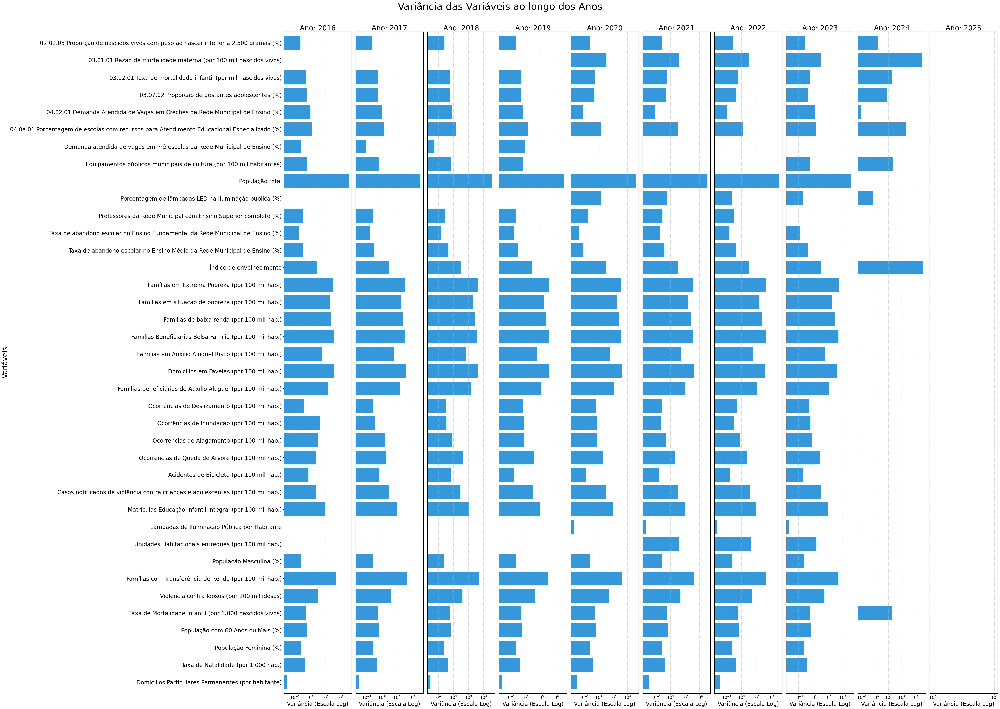

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_variancia(df, title, log_scale=False):
    # 1. Identifica os anos únicos disponíveis no dataframe e os ordena
    anos = sorted(df['Período'].dropna().unique())
    num_anos = len(anos)

    # Identifica apenas as colunas de variáveis (excluindo 'Período' e 'Distrito')
    cols_variaveis = [col for col in df.columns if col not in ['Período', 'Distrito']]

    # 2. Cria a figura com subplots (1 linha, múltiplas colunas)
    fig, axes = plt.subplots(nrows=1, ncols=num_anos, figsize=(5 * num_anos, 35), sharey=True)

    # Garante que axes seja iterável caso haja apenas 1 ano na base
    if num_anos == 1:
        axes = [axes]

    # 3. Loop para calcular a variância e plotar cada ano em seu respectivo eixo (ax)
    for ax, ano in zip(axes, anos):
        # Filtra os dados para o ano do loop
        df_ano = df[df['Período'] == ano].copy()
        
        # Converte todas as colunas de variáveis para numérico de uma vez
        df_ano[cols_variaveis] = df_ano[cols_variaveis].apply(pd.to_numeric, errors='coerce')
        
        # Calcula a variância de cada coluna (ignora NaN automaticamente)
        variancias = df_ano[cols_variaveis].var()

        # Plotagem das barras horizontais
        variancias.plot(
            kind='barh',
            ax=ax,
            color='#3498db', # Azul
            width=0.8
        )

        # Ajustes estéticos individuais
        ax.set_title(f'Ano: {int(ano)}', fontsize=25, pad=5)
        ax.set_xlabel('Variância', fontsize=20)
        ax.tick_params(axis='x', labelsize=15)
        
        # Ativa a escala logarítmica no eixo X se as variáveis tiverem grandezas muito diferentes
        if log_scale:
            ax.set_xscale('log')
            ax.set_xlabel('Variância (Escala Log)', fontsize=20)

        ax.grid(axis='x', linestyle='--', alpha=0.5)
        
        # Mantém o rótulo do eixo Y apenas no primeiro gráfico
        if ax == axes[0]:
            ax.set_ylabel('Variáveis', fontsize=25)
            ax.tick_params(axis='y', labelsize=20)
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', which='both', length=0) 

    # Inverte o eixo Y apenas do primeiro eixo para ler de cima para baixo
    axes[0].invert_yaxis()

    # Adiciona um título geral para a imagem completa
    fig.suptitle('Variância das Variáveis ao longo dos Anos', fontsize=35, y=1.01)

    plt.tight_layout()

    # Salva a imagem
    plt.savefig(
        ROOT / f'analysis/figures/variancia_{title}.png', 
        dpi=300,                              
        bbox_inches='tight',                
        pad_inches=0.2,                     
        facecolor='white',                  
        transparent=False
    )

    plt.show()

plot_variancia(df3sel, 'sel3', log_scale=True)